# Machine Learning Fundamentals
## Unit 06 — Categorical Variables

**Stage 2: Machine Learning | Beginner level | English B2**  
**Dataset:** Melbourne Housing (`melb_data.csv`)  
**Environment:** Google Colab / Jupyter Notebook  
**Libraries:** Pandas, NumPy, Matplotlib, scikit-learn

---

## Business question

Housing data contains numeric measurements and categories such as property type, suburb, and seller. Most scikit-learn models need categorical inputs to be represented numerically. How can we convert these values without losing useful information or creating misleading numeric relationships?

In this lesson, we compare three approaches using the same training/validation split and Random Forest model.

### Learning outcomes

By the end of this notebook, you should be able to:

- Distinguish ordinal and nominal categorical variables.
- Explain why many ML estimators cannot directly use text categories.
- Compare dropping categorical features, ordinal encoding, and one-hot encoding.
- Use `OrdinalEncoder` and `OneHotEncoder` correctly.
- Handle categories that appear in validation data but not in training data.
- Compare strategies with validation MAE while avoiding data leakage.

### Lesson map

1. What are categorical variables?
2. Three encoding approaches
3. Prepare and inspect the dataset
4. Evaluate the approaches consistently
5. Compare results and interpret limitations
6. Practical challenge and readiness check

**Dataset setup:** Upload `melb_data.csv` to your Colab session before running the data-loading cell. The notebook uses historical housing data for teaching; its results are not current market valuations.

---
# 1. Introduction

A **categorical variable** takes a limited number of values that represent groups or labels.

Consider a survey that asks how often you eat breakfast and provides four options: "Never", "Rarely", "Most days", or "Every day". In this case, the data is categorical because responses fall into a fixed set of categories.

If people responded to a survey about which brand of car they owned, the responses might include "Honda", "Toyota", and "Ford". This data is also categorical.

Many machine learning models in Python require numerical inputs. If you provide text categories without preprocessing them, the model may return an error. In this lesson, we'll compare three approaches to prepare categorical data.


## 1.1 Two Types of Categorical Variables

**Ordinal variables** have a meaningful order. For example:

`Never < Rarely < Most days < Every day`

**Nominal variables** have categories with no natural ranking. For example:

`Red`, `Yellow`, and `Green`

The difference matters because some encoding methods assign numbers to categories. Those numbers should not suggest an order that does not exist.


### Practical rule

- Use **ordinal encoding** when the categories have a meaningful order and the chosen model can use that representation appropriately.
- Use **one-hot encoding** for nominal categories with no natural order.
- Do not assume that a category's text label or alphabetical order represents business importance.

For example, `Never`, `Rarely`, `Most days`, and `Every day` have a natural order. `Red`, `Yellow`, and `Green` do not have a general numeric ranking when they describe product color.

---
# 2. Three Approaches

## Approach 1 — Drop Categorical Variables

The easiest approach is to remove categorical columns from the dataset. This can work when those columns do not contain useful information, but it may remove valuable signals that could help the model predict prices.


## Approach 2 — Ordinal Encoding

Ordinal encoding assigns each category an integer. This is a sensible option when the categories have a real order, such as breakfast frequency.

The example below shows the transformation:


<div align="center">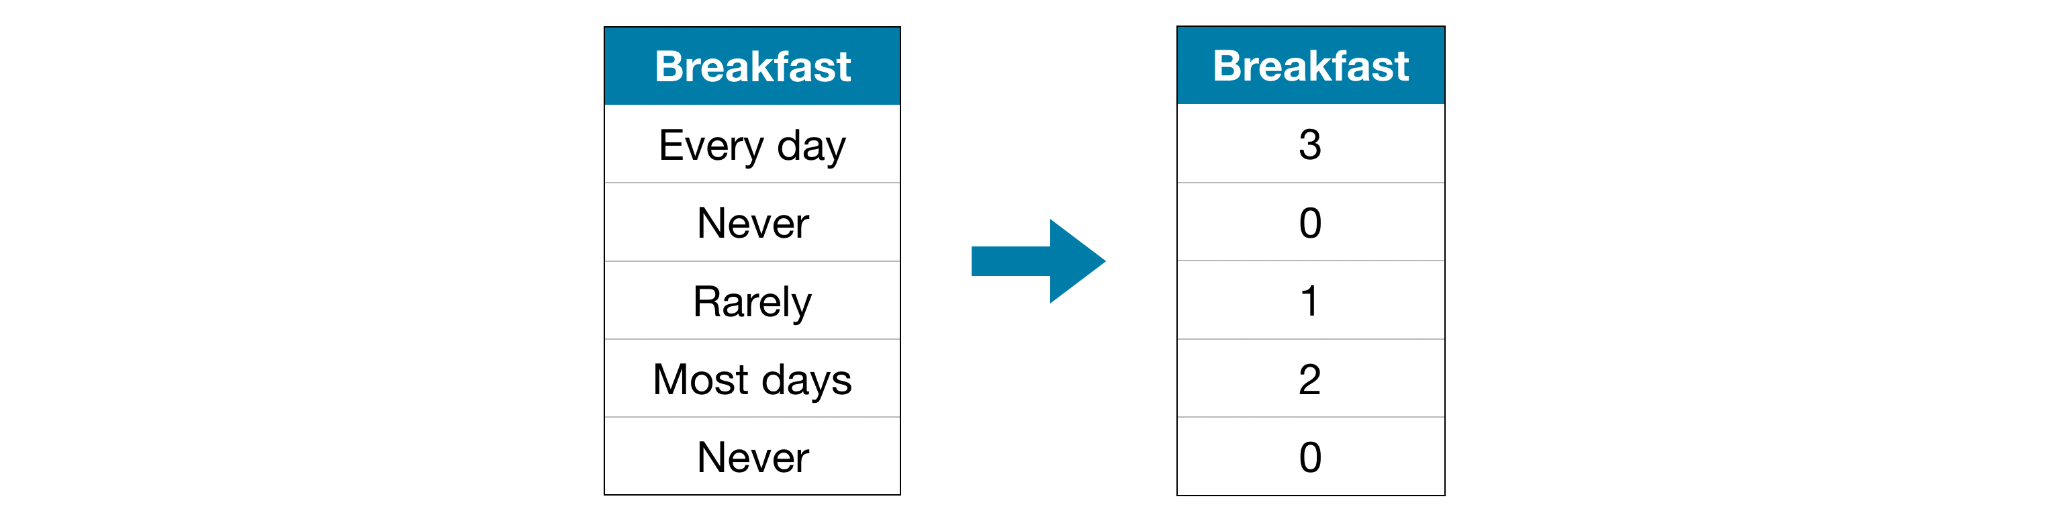</div>

This approach assumes an ordering of the categories: **Never (0) < Rarely (1) < Most days (2) < Every day (3)**. This makes sense because the categories have a clear order.

For nominal variables such as car brand or region name, assigning numbers may create an artificial order. Ordinal encoding can still be tested as a baseline with some models, but it should not be treated as a universal solution for nominal categories.


## Approach 3 — One-Hot Encoding

One-hot encoding creates a new binary column for each category. A value of `1` marks the category present in a row, while `0` marks the other categories.


<div align="center">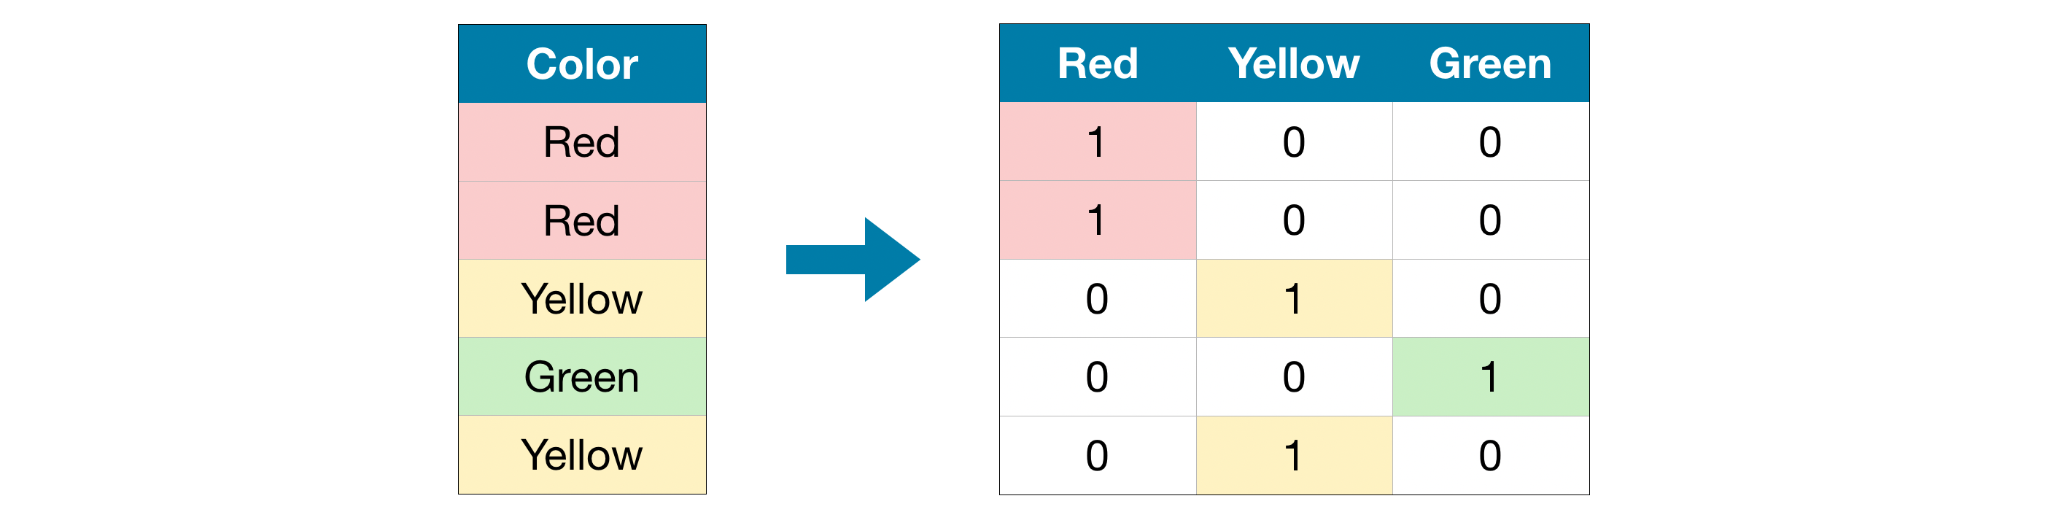</div>

In the original dataset, `Color` is a categorical variable with three categories: `Red`, `Yellow`, and `Green`. The encoded dataset has one column for each category.

Unlike ordinal encoding, one-hot encoding does not assume an ordering between categories. It is often a good choice for nominal variables with a manageable number of categories.

However, one-hot encoding can create many columns when a feature has a large number of unique values. This is why we should check the **cardinality** of categorical columns before choosing an encoding method.


## 2.1 Quick Comparison

| Approach | How it works | Most suitable when |
|---|---|---|
| Drop categorical variables | Removes text/category columns | Categories provide little useful information |
| Ordinal encoding | Maps each category to an integer | Categories have a meaningful order |
| One-hot encoding | Creates a binary column for each category | Categories have no natural order and cardinality is manageable |

There is no single best method for every dataset. We will compare the approaches using validation MAE.


---
# 3. Prepare the Data

As in the previous tutorial, we will work with the Melbourne Housing dataset.

We will:
1. Separate the target (`Price`) from the predictors.
2. Split the data into training and validation subsets.
3. Drop columns with missing values, using the same columns for both sets.
4. Select categorical columns with relatively low cardinality and keep numeric columns.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Read the data
melbourne_file_path = 'melb_data.csv'
data = pd.read_csv(melbourne_file_path)

# Separate target from predictors
y = data.Price
X = data.drop(['Price'], axis=1)

# Divide data into training and validation subsets
X_train_full, X_valid_full, y_train, y_valid = train_test_split(
    X,
    y,
    train_size=0.8,
    test_size=0.2,
    random_state=0
)

# Drop columns with missing values
cols_with_missing = [
    col for col in X_train_full.columns
    if X_train_full[col].isnull().any()
]
X_train_full = X_train_full.drop(columns=cols_with_missing)
X_valid_full = X_valid_full.drop(columns=cols_with_missing)

# Cardinality means the number of unique values in a column
# Select categorical columns with relatively low cardinality
low_cardinality_cols = [
    col for col in X_train_full.columns
    if X_train_full[col].nunique() < 10
    and X_train_full[col].dtype == 'object'
]

# Select numerical columns
numerical_cols = [
    col for col in X_train_full.columns
    if X_train_full[col].dtype in ['int64', 'float64']
]

# Keep selected columns only
my_cols = low_cardinality_cols + numerical_cols
X_train = X_train_full[my_cols].copy()
X_valid = X_valid_full[my_cols].copy()

print("Selected categorical columns:", low_cardinality_cols)
print("Number of numerical columns:", len(numerical_cols))
print("Training shape:", X_train.shape)
print("Validation shape:", X_valid.shape)

## 3.1 Inspect the Training Data

We take a look at the training data with `head()`. This helps us understand what the rows and columns represent before encoding them.


In [ ]:
X_train.head()

Next, we obtain a list of categorical variables by checking the data type of each column. In this dataset, the `object` dtype indicates text columns, which represent categories for this example.


In [ ]:
# Get the list of categorical variables
s = (X_train.dtypes == 'object')
object_cols = list(s[s].index)

print("Categorical variables:")
print(object_cols)

---
# 4. Evaluate the Approaches

We define a function `score_dataset()` to compare the three approaches. It trains a Random Forest model and returns the Mean Absolute Error (MAE) on the validation data.

A lower MAE means smaller average absolute prediction errors on the validation set.


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

def score_dataset(X_train_processed, X_valid_processed, y_train, y_valid):
    model = RandomForestRegressor(
        n_estimators=100,
        random_state=0,
        n_jobs=-1
    )
    model.fit(X_train_processed, y_train)
    predictions = model.predict(X_valid_processed)
    return mean_absolute_error(y_valid, predictions)

## Approach 1 — Drop Categorical Variables

We drop the text columns by selecting only non-object columns.


In [ ]:
drop_X_train = X_train.select_dtypes(exclude=['object'])
drop_X_valid = X_valid.select_dtypes(exclude=['object'])

mae_drop = score_dataset(
    drop_X_train, drop_X_valid, y_train, y_valid
)

print("MAE from Approach 1 (Drop categorical variables):")
print(f"${mae_drop:,.2f}")

The original lesson reports an MAE of approximately **$175,703** for this approach. Your result may differ depending on the dataset version and software environment.


## Approach 2 — Ordinal Encoding

Scikit-learn has an `OrdinalEncoder` class that converts categories into integer codes. We fit the encoder on the training data and then use the same encoder to transform the validation data.


In [ ]:
from sklearn.preprocessing import OrdinalEncoder

# Make copies to keep the original data unchanged
label_X_train = X_train.copy()
label_X_valid = X_valid.copy()

# Fit the encoder on training categories and transform both sets
ordinal_encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)
label_X_train[object_cols] = ordinal_encoder.fit_transform(
    X_train[object_cols]
)
label_X_valid[object_cols] = ordinal_encoder.transform(
    X_valid[object_cols]
)

mae_ordinal = score_dataset(
    label_X_train, label_X_valid, y_train, y_valid
)

print("MAE from Approach 2 (Ordinal Encoding):")
print(f"${mae_ordinal:,.2f}")

The original lesson reports an MAE of approximately **$165,936** for ordinal encoding. In that example, this approach performed better than dropping categorical columns.

The encoder assigns category codes based on the categories it learns from the training data. For nominal categories, these numbers are labels rather than meaningful measurements. Tree-based models may still produce useful results, but one-hot encoding is often a safer starting point when there is no natural order.


## Approach 3 — One-Hot Encoding

We use scikit-learn's `OneHotEncoder`. The setting `handle_unknown='ignore'` prevents an error if validation data contains a category that did not appear in the training data.

The current scikit-learn API uses `sparse_output=False` to return a dense array. This is useful for this introductory example; for large datasets, sparse output can use less memory.


In [ ]:
from sklearn.preprocessing import OneHotEncoder

# Apply one-hot encoding to categorical columns
# `sparse_output` is used by current scikit-learn versions.
# Older versions used the parameter name `sparse`.
try:
    OH_encoder = OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    )
except TypeError:
    OH_encoder = OneHotEncoder(
        handle_unknown='ignore',
        sparse=False
    )

OH_cols_train = pd.DataFrame(
    OH_encoder.fit_transform(X_train[object_cols]),
    index=X_train.index,
    columns=OH_encoder.get_feature_names_out(object_cols)
)
OH_cols_valid = pd.DataFrame(
    OH_encoder.transform(X_valid[object_cols]),
    index=X_valid.index,
    columns=OH_encoder.get_feature_names_out(object_cols)
)

# Remove categorical columns; they will be replaced by encoded columns
num_X_train = X_train.drop(columns=object_cols)
num_X_valid = X_valid.drop(columns=object_cols)

# Add one-hot encoded columns to numerical features
OH_X_train = pd.concat([num_X_train, OH_cols_train], axis=1)
OH_X_valid = pd.concat([num_X_valid, OH_cols_valid], axis=1)

mae_onehot = score_dataset(
    OH_X_train, OH_X_valid, y_train, y_valid
)

print("MAE from Approach 3 (One-Hot Encoding):")
print(f"${mae_onehot:,.2f}")

The original lesson reports an MAE of approximately **$166,089** for one-hot encoding. In that example, the ordinal encoding and one-hot encoding results are very close.

**Version note:** If you use an older scikit-learn version that does not support `sparse_output`, replace it with `sparse=False`.


---
# 5. Compare Results

The following are reference scores from the original lesson. Use the values printed by your own notebook as the final results for your environment.


In [ ]:
results_df = pd.DataFrame({
    "Approach": [
        "Drop categorical variables",
        "Ordinal encoding",
        "One-hot encoding"
    ],
    "Validation MAE (AUD)": [
        mae_drop,
        mae_ordinal,
        mae_onehot
    ]
}).sort_values("Validation MAE (AUD)").reset_index(drop=True)

display(results_df.style.format({"Validation MAE (AUD)": "AUD {:,.0f}"}))

best_result = results_df.iloc[0]
print(
    f"Best approach in this run: {best_result['Approach']} "
    f"(Validation MAE: AUD {best_result['Validation MAE (AUD)']:,.0f})"
)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(results_df["Approach"], results_df["Validation MAE (AUD)"])
ax.set_title("Validation MAE by Categorical-Data Strategy")
ax.set_ylabel("Mean Absolute Error (AUD)")
ax.tick_params(axis="x", rotation=12)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretation:** Use the dynamically generated results above to discuss this run. Lower MAE means lower average absolute prediction error on this validation set. The historical reference scores below are included for context; they may not exactly match your environment.

| Approach | Reference validation MAE |
|---|---:|
| Drop categorical variables | $175,703 |
| Ordinal encoding | $165,936 |
| One-hot encoding | $166,089 |

In this example, dropping the categorical columns performed worst because it had the highest MAE. The ordinal and one-hot encoding scores were very close, so there was no large difference between them in this experiment.

In general, one-hot encoding is often a strong starting point for nominal categories, while ordinal encoding is appropriate when categories have a meaningful order. The best choice depends on the dataset and model.


## 5.1 Review Questions

1. What makes a variable categorical?
2. What is the difference between ordinal and nominal variables?
3. Why can ordinal encoding be misleading for categories such as color or region?
4. What does `handle_unknown='ignore'` do in `OneHotEncoder`?
5. Why do we fit the encoder on training data and then transform validation data?
6. Which approach achieved the lowest MAE in the original example?


---
# 6. Conclusion and Practice

The world is filled with categorical data. You will be a much more effective data scientist if you know how to use this common data type.

- **Drop categorical variables** only when removing them is a reasonable choice.
- **Ordinal encode** categories that have a meaningful order.
- **One-hot encode** nominal categories when the number of unique values is manageable.
- Use validation MAE to compare the methods on your data.
- Fit preprocessing steps on training data only, then apply them to validation data to avoid data leakage.

## Your Turn

Put your new skills to work in the next exercise.

**[Open Kaggle — Intermediate Machine Learning: Categorical Variables](https://www.kaggle.com/learn/intermediate-machine-learning/lesson/3)**

[Open the full Intermediate Machine Learning course](https://www.kaggle.com/learn/intermediate-machine-learning)

### Practical challenge

1. Run all three approaches and record their MAE scores.
2. Identify the approach with the lowest validation MAE.
3. Explain why the score from dropping categorical variables may be worse.
4. Choose an ordinal variable and explain why its categories have a meaningful order.
5. Try a feature with many unique categories and discuss how one-hot encoding changes the number of columns.

### Practice checklist

- [ ] I can identify categorical variables.
- [ ] I can explain cardinality.
- [ ] I can distinguish ordinal and nominal variables.
- [ ] I can apply ordinal encoding.
- [ ] I can apply one-hot encoding.
- [ ] I can compare encoding methods using validation MAE.

## Key takeaway

**Categorical data must be represented in a form that a model can use. Choose the encoding method based on the meaning of the categories, then compare performance on validation data.**


---
## References

- [Kaggle — Intermediate Machine Learning: Categorical Variables](https://www.kaggle.com/learn/intermediate-machine-learning/lesson/3)
- [scikit-learn — OrdinalEncoder documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OrdinalEncoder.html)
- [scikit-learn — OneHotEncoder documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
